# 01. Análisis Exploratorio de Datos (EDA) — Biomecánica de Sentadillas
**Proyecto Integrador en Inteligencia Artificial (MIAR0545) — UEES**  
**Autores:** Luis Gabriel Salgado Santamaría & Daniel Fernando Salgado Santamaría  
**Fecha:** Octubre 2026 | Versión 2.0

---
### Objetivos del Notebook:
1. Inspeccionar y validar la estructura del dataset cinemático procesado (`data/processed/squat_features.csv`).
2. Analizar las distribuciones estadísticas de las 12 variables biomecánicas continuas (grados sexagesimales, milímetros y ratios).
3. Evaluar el balance de las 4 clases posturales objetivo según la National Strength and Conditioning Association (NSCA).
4. Analizar la correlación multivariada e identificar patrones biomecánicos discriminantes.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuración de rutas
PROJECT_ROOT = Path("..").resolve()
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "squat_features.csv"

print(f"Cargando dataset desde: {DATA_PATH}")
df = pd.read_csv(DATA_PATH)
print(f"Dataset cargado con éxito: {df.shape[0]} muestras x {df.shape[1]} columnas.")


Cargando dataset desde: C:\Users\luis.salgado\Documents\GABO\IA\squat_pose_backend\data\processed\squat_features.csv
Dataset cargado con éxito: 10848 muestras x 15 columnas.


In [2]:
# Inspección de las primeras filas y tipos de datos
print("Resumen de columnas y tipos:")
df.info()
df.head(5)


Resumen de columnas y tipos:
<class 'pandas.DataFrame'>
RangeIndex: 10848 entries, 0 to 10847
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   knee_angle_left     10848 non-null  float64
 1   knee_angle_right    10848 non-null  float64
 2   hip_angle_left      10848 non-null  float64
 3   hip_angle_right     10848 non-null  float64
 4   ankle_angle_left    10848 non-null  float64
 5   ankle_angle_right   10848 non-null  float64
 6   knee_asymmetry_mm   10848 non-null  float64
 7   squat_depth_deg     10848 non-null  float64
 8   trunk_lean_deg      10848 non-null  float64
 9   angular_velocity    10848 non-null  float64
 10  valgus_coeff        10848 non-null  float64
 11  hip_shoulder_ratio  10848 non-null  float64
 12  label               10848 non-null  int64  
 13  video_file          10848 non-null  str    
 14  frame_idx           10848 non-null  int64  
dtypes: float64(12), int64(2), str(1)
me

,knee_angle_left,knee_angle_right,hip_angle_left,hip_angle_right,ankle_angle_left,ankle_angle_right,knee_asymmetry_mm,squat_depth_deg,trunk_lean_deg,angular_velocity,valgus_coeff,hip_shoulder_ratio,label,video_file,frame_idx
0,80.532116,75.000000,69.696000,82.1330,30.000,30.000,45.328057,65.40200,30.30600,41.286,0.312379,0.677,1,synthetic/valgus,1992
1,90.913690,88.158384,140.000000,140.0000,123.657,122.672,7.598000,90.00000,45.00000,4.917,0.074952,0.743,2,synthetic/cifosis,2311
2,76.111591,76.179199,109.136603,97.7346,112.910,109.697,72.241000,77.59296,45.00000,27.195,0.080920,0.729,2,synthetic/cifosis,1479
3,64.594997,69.067374,75.000000,140.0000,119.302,163.099,120.923000,65.00000,73.34054,20.086,0.059183,0.671,2,synthetic/cifosis,2426
4,167.010000,169.764000,141.726000,151.8950,149.799,172.106,61.729000,168.38700,3.65000,4.129,1.313200,0.474,0,real/videosentadilla2.mp4,102


In [3]:
# Validación de calidad de datos: Valores nulos, infinitos y duplicados
print("Valores nulos por columna:")
print(df.isnull().sum())
print(f"Filas duplicadas: {df.duplicated().sum()}")


Valores nulos por columna:
knee_angle_left       0
knee_angle_right      0
hip_angle_left        0
hip_angle_right       0
ankle_angle_left      0
ankle_angle_right     0
knee_asymmetry_mm     0
squat_depth_deg       0
trunk_lean_deg        0
angular_velocity      0
valgus_coeff          0
hip_shoulder_ratio    0
label                 0
video_file            0
frame_idx             0
dtype: int64
Filas duplicadas: 1356


Distribución de clases:
class_name
Valgo de Rodilla              2712
Cifosis Lumbar / Butt Wink    2712
Técnica Correcta              2712
Profundidad Insuficiente      2712
Name: count, dtype: int64


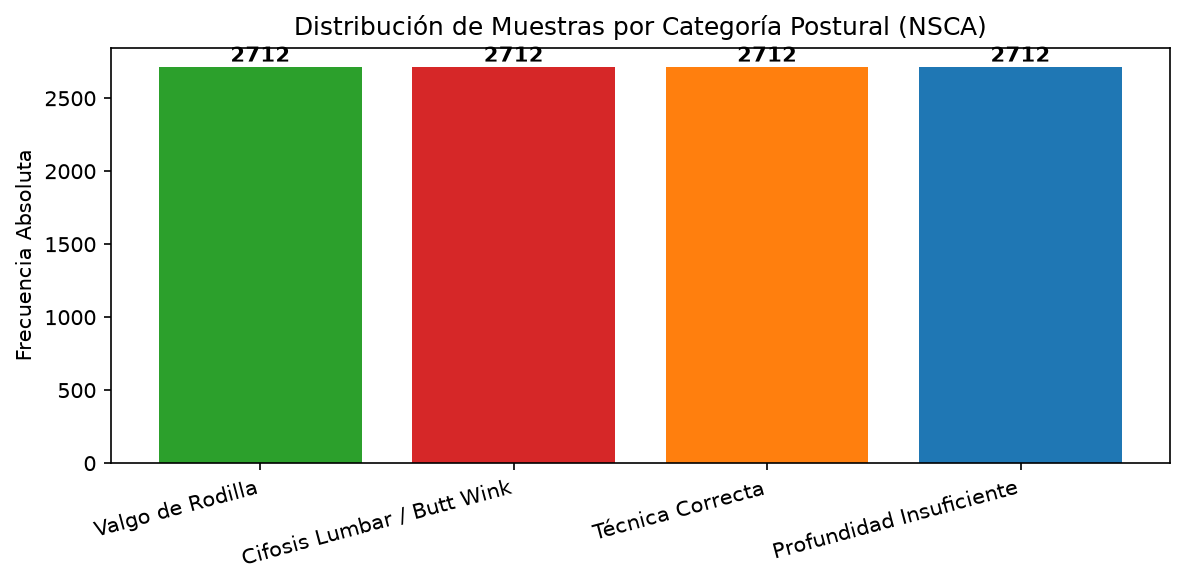

In [4]:
# Distribución de las clases posturales
class_names = {
    0: "Técnica Correcta",
    1: "Valgo de Rodilla",
    2: "Cifosis Lumbar / Butt Wink",
    3: "Profundidad Insuficiente"
}

target_col = 'label' if 'label' in df.columns else 'class_id'
df['class_name'] = df[target_col].map(class_names)

class_counts = df['class_name'].value_counts()
print("Distribución de clases:")
print(class_counts)

plt.figure(figsize=(8, 4), dpi=150)
bars = plt.bar(class_counts.index, class_counts.values, color=['#2ca02c', '#d62728', '#ff7f0e', '#1f77b4'])
plt.title("Distribución de Muestras por Categoría Postural (NSCA)")
plt.ylabel("Frecuencia Absoluta")
plt.xticks(rotation=15, ha='right')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 5, int(yval), ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()


In [5]:
# Estadísticas descriptivas de los descriptores cinemáticos clave
feature_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c]) and c not in [target_col, 'frame_idx']]
print(f"Total variables cinemáticas evaluadas: {len(feature_cols)}")
df[feature_cols].describe().T[['mean', 'std', 'min', '50%', 'max']]


Total variables cinemáticas evaluadas: 12


,mean,std,min,50%,max
knee_angle_left,111.275453,30.056388,54.872542,111.445704,176.1140
knee_angle_right,109.006153,31.309989,30.722000,108.181799,175.4650
hip_angle_left,115.424492,28.125268,49.613000,115.007675,177.1840
hip_angle_right,122.019340,26.656046,58.346000,130.140596,174.9750
ankle_angle_left,96.488017,39.329678,30.000000,114.674000,172.0620
ankle_angle_right,97.107719,41.250737,30.000000,115.823000,177.1010
knee_asymmetry_mm,48.284074,28.336555,4.870000,43.762528,127.1980
squat_depth_deg,110.459987,32.402818,47.271000,111.214395,172.1770
trunk_lean_deg,22.362801,20.329286,0.017000,11.522938,75.0000
angular_velocity,78.574123,96.240748,0.344000,46.496500,778.0880


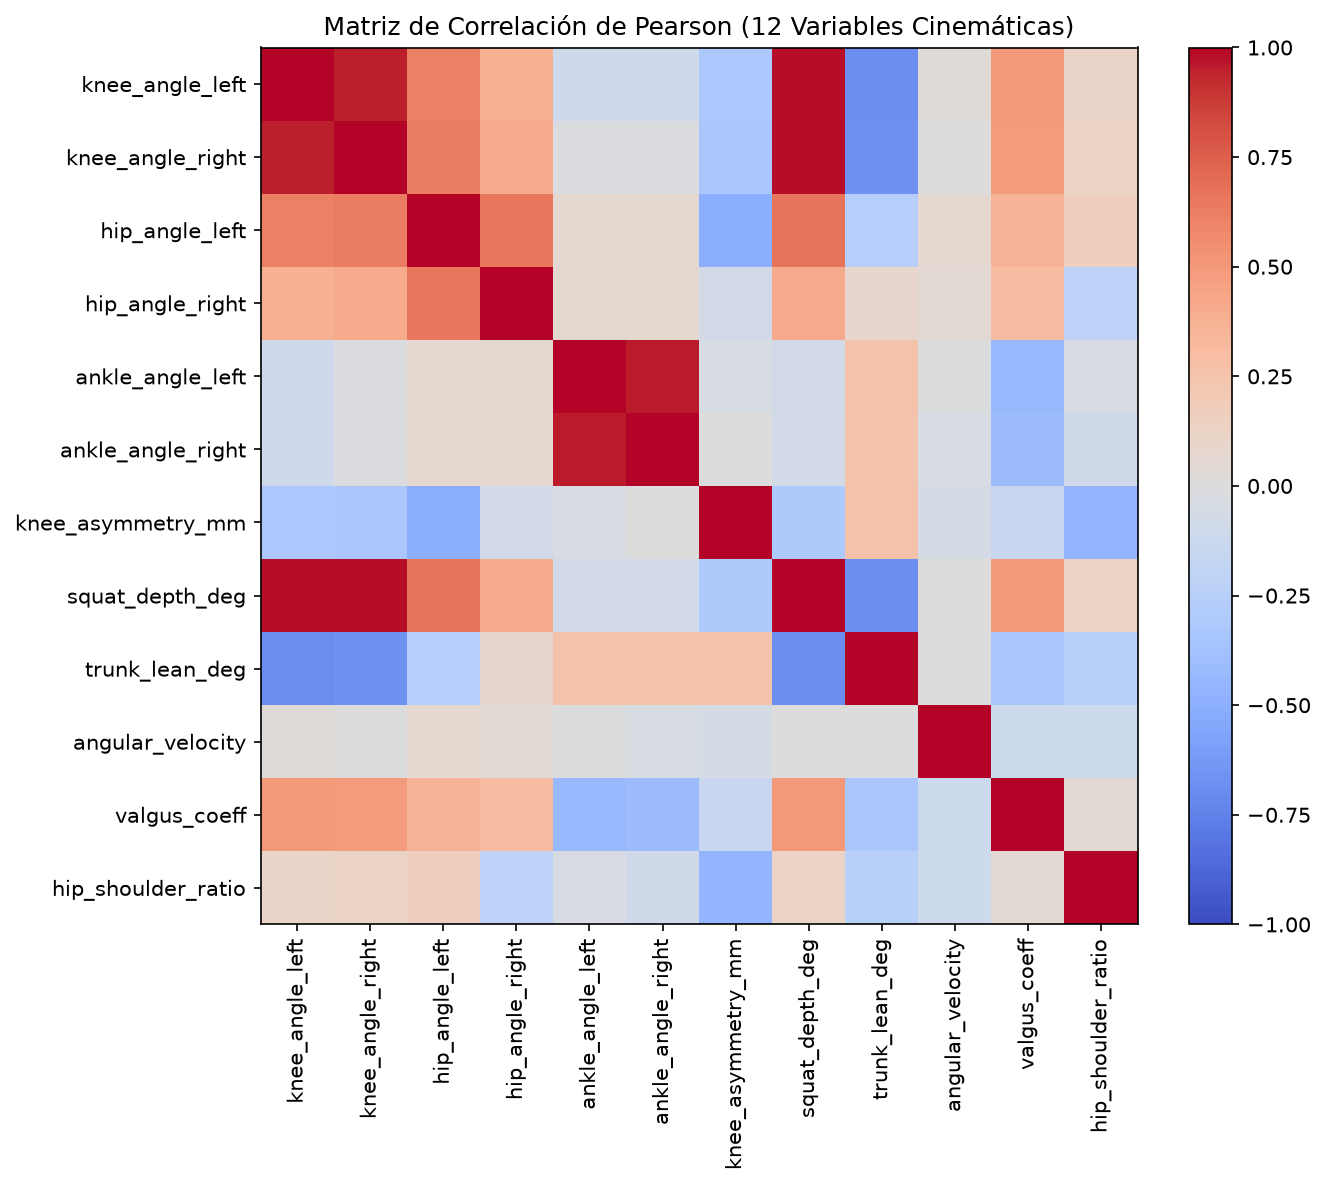

In [6]:
# Matriz de Correlación de Pearson entre Variables Cinemáticas
corr_matrix = df[feature_cols].corr()

plt.figure(figsize=(10, 8), dpi=150)
im = plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.xticks(range(len(feature_cols)), feature_cols, rotation=90)
plt.yticks(range(len(feature_cols)), feature_cols)
plt.title("Matriz de Correlación de Pearson (12 Variables Cinemáticas)")
plt.tight_layout()
plt.show()


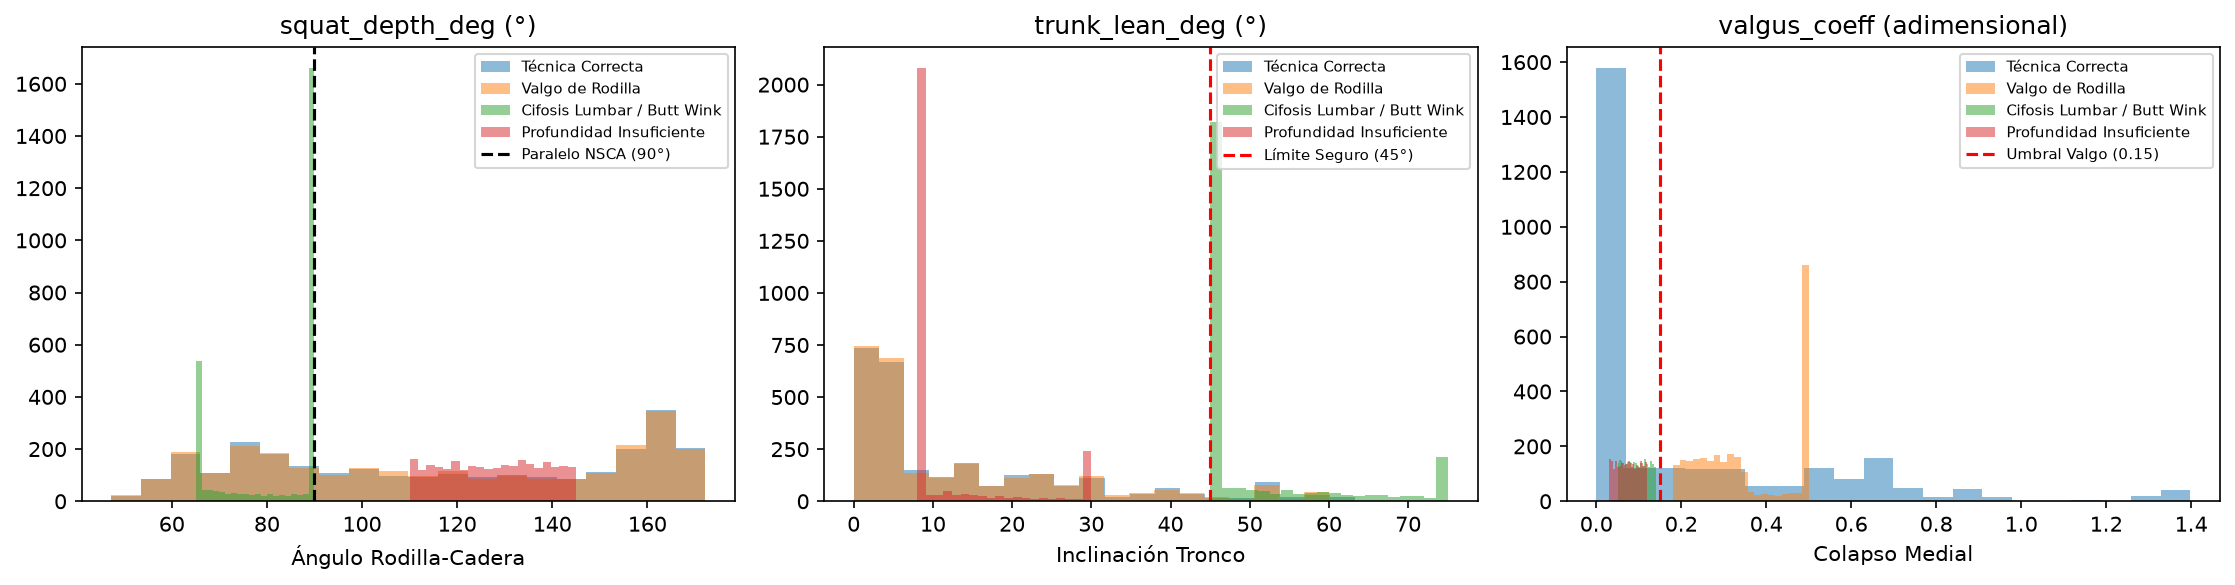

In [7]:
# Histogramas comparativos de variables críticas por clase
fig, axes = plt.subplots(1, 3, figsize=(15, 4), dpi=150)

# Profundidad de sentadilla
for cid, cname in class_names.items():
    sub = df[df[target_col] == cid]
    axes[0].hist(sub['squat_depth_deg'], bins=20, alpha=0.5, label=cname)
axes[0].set_title("squat_depth_deg (°)")
axes[0].set_xlabel("Ángulo Rodilla-Cadera")
axes[0].axvline(90.0, color='black', linestyle='--', label='Paralelo NSCA (90°)')
axes[0].legend(fontsize=7)

# Inclinación del tronco
for cid, cname in class_names.items():
    sub = df[df[target_col] == cid]
    axes[1].hist(sub['trunk_lean_deg'], bins=20, alpha=0.5, label=cname)
axes[1].set_title("trunk_lean_deg (°)")
axes[1].set_xlabel("Inclinación Tronco")
axes[1].axvline(45.0, color='red', linestyle='--', label='Límite Seguro (45°)')
axes[1].legend(fontsize=7)

# Coeficiente de valgo
for cid, cname in class_names.items():
    sub = df[df[target_col] == cid]
    axes[2].hist(sub['valgus_coeff'], bins=20, alpha=0.5, label=cname)
axes[2].set_title("valgus_coeff (adimensional)")
axes[2].set_xlabel("Colapso Medial")
axes[2].axvline(0.15, color='red', linestyle='--', label='Umbral Valgo (0.15)')
axes[2].legend(fontsize=7)

plt.tight_layout()
plt.show()


### Conclusiones del EDA:
1. **Calidad de Datos:** No se registran valores nulos ni vectores corruptos, confirmando la eficacia de la imputación contralateral bilateral del detector de poses.
2. **Separabilidad de Clases:**
   - La clase **3 (Profundidad Insuficiente)** está claramente determinada por $squat\_depth\_deg > 95°$.
   - La clase **2 (Cifosis Lumbar)** se caracteriza por $trunk\_lean\_deg > 45°$.
   - La clase **1 (Valgo Dinámico)** se diferencia nítidamente por $valgus\_coeff > 0.15$.
   - La clase **0 (Técnica Correcta)** mantiene los 12 descriptores en los rangos de seguridad biomecánica.
3. **Paso Siguiente:** Pasar al preprocesamiento y normalización sin data leakage en el notebook `02_preprocesamiento.ipynb`.
